# 01 · Explore ERA5-Land winter precipitation

Phase 1 of `ACTION_PLAN.md`. Winter (DJF) precipitation per region for every
winter from 1950-51 to 2025-26, with El Niño winters highlighted, a map of the
1997-98 winter against the all-winters mean, and the same series classified by
RONI next to ONI for the index decision. Seven regions: PNW, BC and AB
(primary), Alaska and Yukon (north, added 2026-10-04), NorCal and SoCal
(contrast).

**Climate data only.** No fire data is opened anywhere in this notebook; the
analysis plan is not frozen yet.

All loading, unit conversion, masking and averaging comes from `src/`
(`src.era5`, `src.geo.regional_mean`); figures are written to
`results/figures/` by the code below.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src import era5, figures, winter_figures
from src.config import DATA_PROCESSED, ENSO_INDEX, ENSO_INDEX_URLS
from src.describe import phase_summary
from src.download_oni import load_winters
from src.geo import regional_mean
from src.regions import load_regions
import xarray as xr

pd.set_option("display.precision", 2)

C:\Users\dacek\miniforge3\envs\whiplash\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load and convert

`open_era5` opens the 77 yearly files of each download domain (main:
California to Alberta; north: Alaska and Yukon), drops the leftover `expver` and
`number` coordinates, snaps the grid to its nominal 0.1° values and converts
units: precipitation m/day → mm/month using each month's length (leap years
included), temperature K → °C, SWE m → mm.

Masks use the cell-centre rule; regional means are cos(latitude)-weighted via
`src.geo.regional_mean`.

In [2]:
regions = load_regions()
domains = era5.assign_domains(regions)
datasets = era5.open_domains(list(dict.fromkeys(domains)))
for name, ds in datasets.items():
    print(name, ds["tp"].attrs["units"], dict(ds.sizes),
          str(ds.valid_time.values[0])[:7], "to", str(ds.valid_time.values[-1])[:7])
domains.to_frame()

main mm/month {'valid_time': 919, 'latitude': 286, 'longitude': 311} 1950-01 to 2026-07
north mm/month {'valid_time': 919, 'latitude': 206, 'longitude': 456} 1950-01 to 2026-07


,domain
PNW,main
BC,main
AB,main
AK,north
YT,north
NorCal,main
SoCal,main


Check: the two domains overlap south of 60.5°N (140-123.5°W). Both are cut
from the same 0.1° ERA5-Land grid, so overlapping cells should agree. They
match to float32 rounding, not bit for bit: the largest differences are about
7e-7 of the value (6e-5 mm/month of precipitation, 2.4e-4 K of temperature),
consistent with the GRIB packing of each request depending on its area (first
measured 2026-10-04). The check allows a relative 1e-5 or 0.001 in the
variable's units (temperature crosses 0 °C), far above rounding
and far below any real data difference, and requires the land/ocean pattern
to match exactly.

In [3]:
for var in ["tp", "t2m", "sd"]:
    a, b = xr.align(datasets["main"][var], datasets["north"][var], join="inner")
    a, b = a.load(), b.load()
    assert bool((a.isnull() == b.isnull()).all()), f"{var}: land/ocean cells differ"
    diff = abs(a - b).max().item()
    print(f"{var}: {a.sizes['latitude']} x {a.sizes['longitude']} cells x "
          f"{a.sizes['valid_time']} months; max |difference| {diff:.3g} {a.attrs['units']}")
    np.testing.assert_allclose(b.values, a.values, rtol=1e-5, atol=1e-3, equal_nan=True)

tp: 96 x 166 cells x 919 months; max |difference| 5.91e-05 mm/month


t2m: 96 x 166 cells x 919 months; max |difference| 0.000244 degC


sd: 96 x 166 cells x 919 months; max |difference| 0 mm


## DJF precipitation per region, every winter

Winter labelled Y = December of Y-1 plus January and February of Y, paired
with DJF ENSO value Y and fire season Y. Classification uses `ENSO_INDEX` from
`src/config.py`.

In [4]:
winters = pd.read_csv(DATA_PROCESSED / "el_nino_winters.csv")
table, cells = era5.build_winter_precip_table(regions, winters, datasets)
table.to_csv(era5.OUT, index=False)
print(f"{len(table)} rows; {table['year'].nunique()} winters; index {ENSO_INDEX}")
display(cells)
table.head()

532 rows; 76 winters; index RONI


,domain,cells,cells_with_data
region,,,
PNW,main,7361,7331
BC,main,13395,13316
AB,main,9461,9461
AK,north,27711,27021
YT,north,8753,8740
NorCal,main,2820,2802
SoCal,main,1312,1297


,region,year,winter,precip_djf_mm,enso_index,enso_djf,phase,strong
0,PNW,1951,1950-1951,417.21,RONI,-0.28,neutral,False
1,PNW,1952,1951-1952,373.23,RONI,0.65,el_nino,False
2,PNW,1953,1952-1953,518.65,RONI,0.40,neutral,False
3,PNW,1954,1953-1954,449.80,RONI,0.63,el_nino,False
4,PNW,1955,1954-1955,259.01,RONI,-0.12,neutral,False


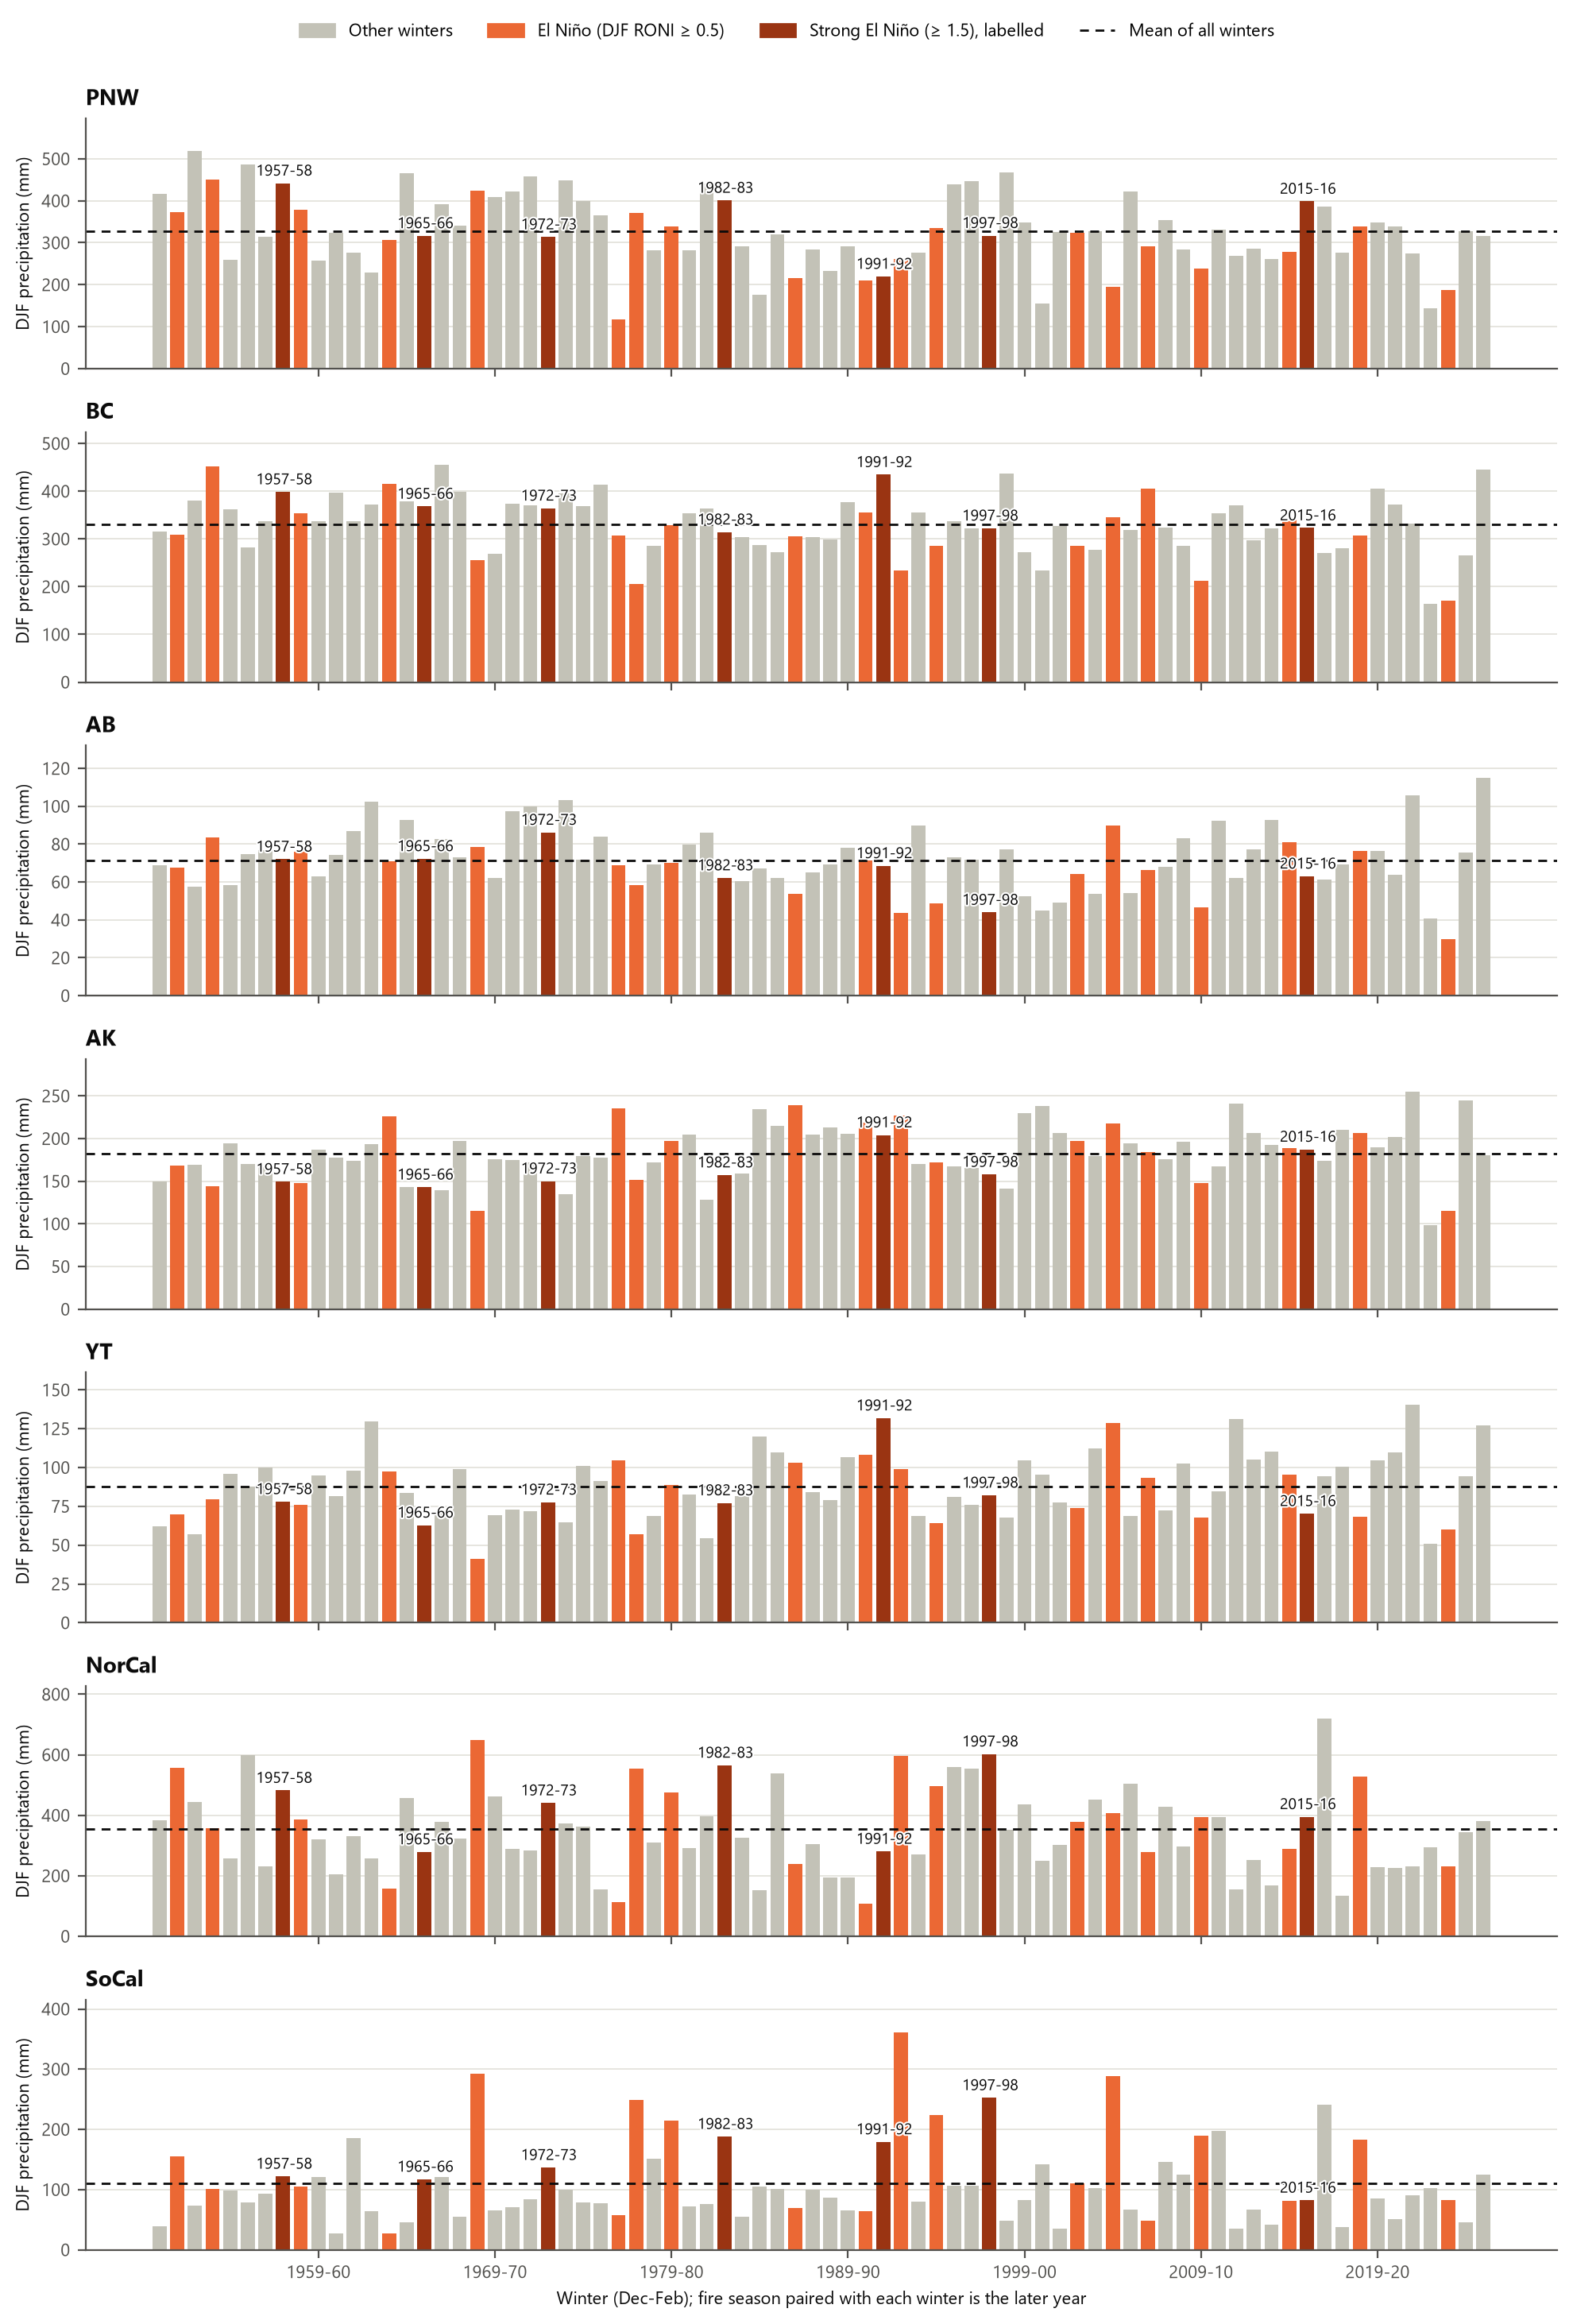

In [5]:
# Figure code lives in src/winter_figures.py (python -m src.winter_figures).
out = winter_figures.series_figure(table)
display(Image(out))

## 1997-98 against the all-winters mean

Baseline: the mean of all 76 winters, 1950-51 to 2025-26 (owner's choice,
2026-10-04; 1997-98 is one of the 76). Shown as percent of normal on a log
scale, so 50% and 200% are equally far from normal. Region labels give each
region's regional total as % of its own mean.

region
AB         61.0
AK         86.0
BC         97.0
NorCal    170.0
PNW        97.0
SoCal     228.0
YT         94.0
Name: 1997-98, % of mean, dtype: float64

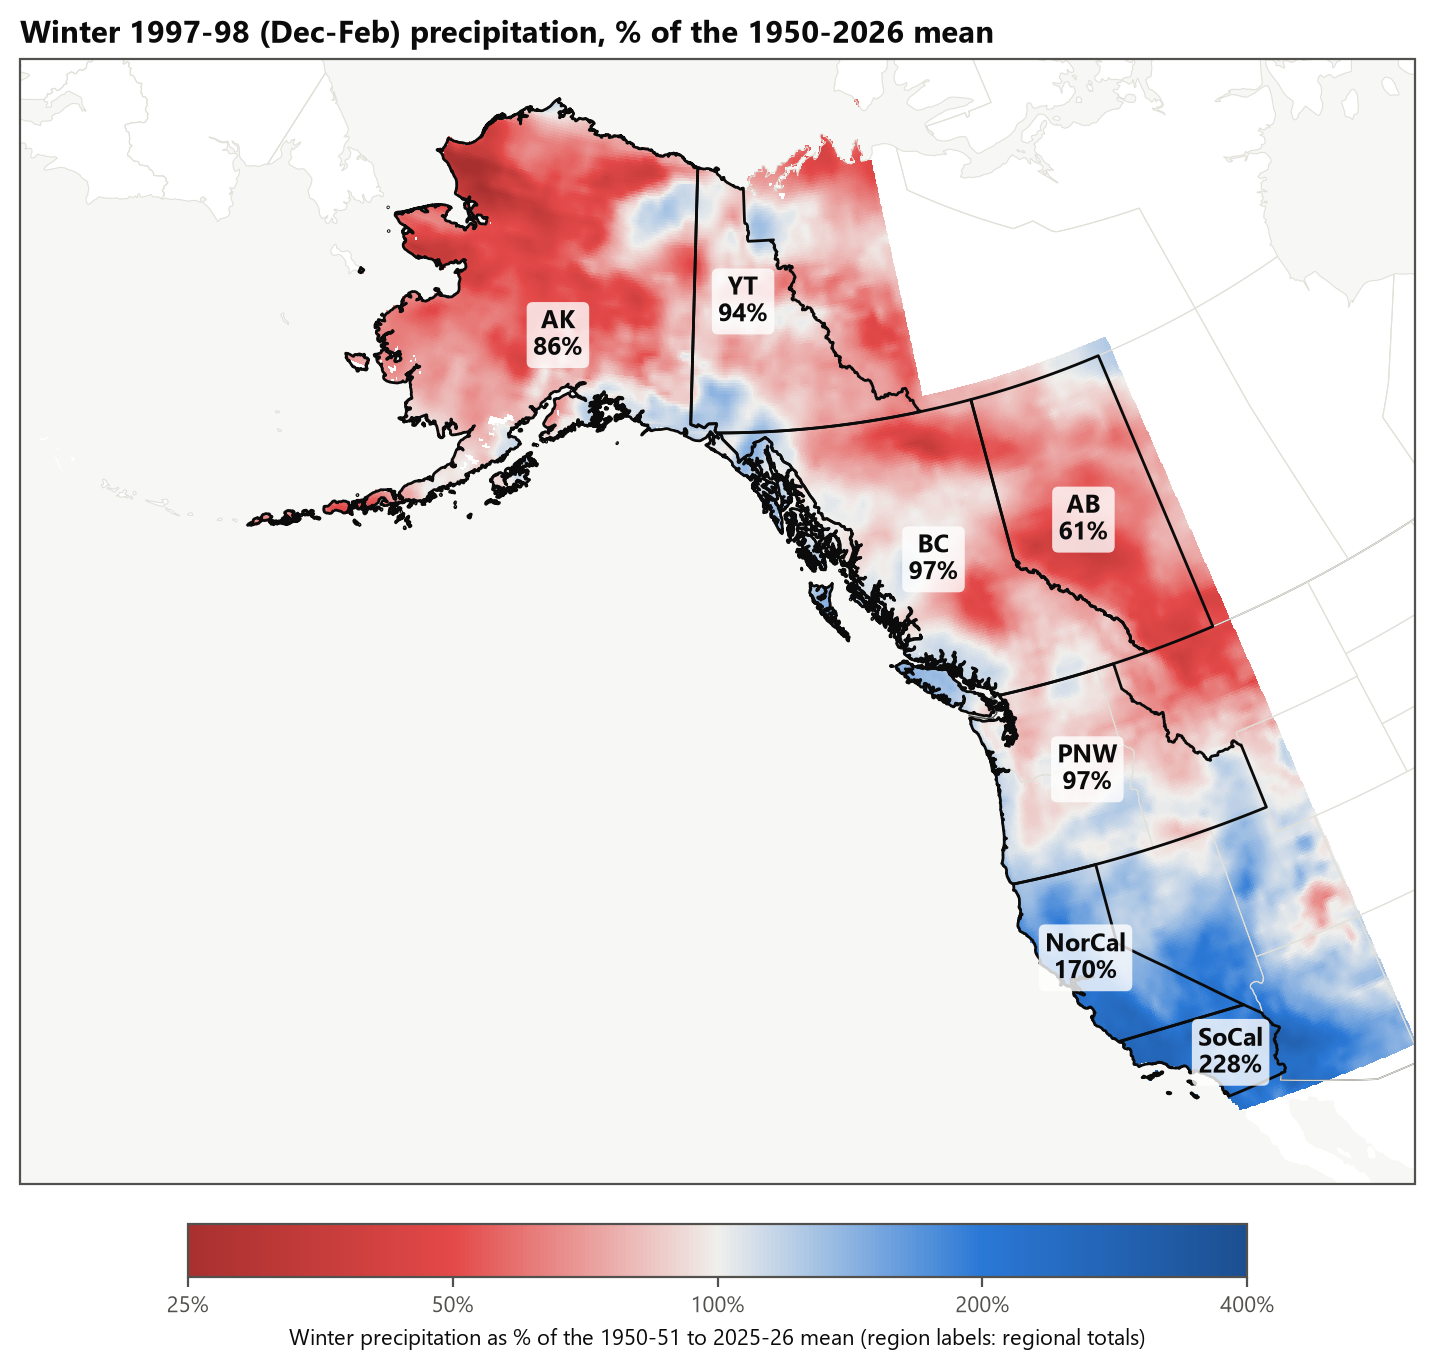

In [6]:
out, region_pct = winter_figures.map_figure(table, datasets, regions)
display(region_pct.round(0).rename("1997-98, % of mean"))
display(Image(out))

## ONI next to RONI (exploration for the index decision)

The same precipitation series, classified by each index. RONI subtracts the
tropical-mean SST anomaly, so it removes the warming trend that makes recent
ONI values run warm (`docs/plan_deviations.md` D15). Climate data only.

In [7]:
classes = {name: load_winters(name) for name in ENSO_INDEX_URLS}
tables = winter_figures.series_by_index(table, classes)

changed = classes["ONI"].merge(classes["RONI"], on=["year", "winter"], suffixes=("_oni", "_roni"))
changed = changed[(changed["phase_oni"] != changed["phase_roni"])
                  | (changed["strong_oni"] != changed["strong_roni"])]
print(f"{len(changed)} of {len(classes['ONI'])} winters change class")
changed[["winter", "enso_djf_oni", "phase_oni", "strong_oni",
         "enso_djf_roni", "phase_roni", "strong_roni"]]

17 of 76 winters change class


,winter,enso_djf_oni,phase_oni,strong_oni,enso_djf_roni,phase_roni,strong_roni
0,1950-1951,-0.66,la_nina,False,-0.28,neutral,False
3,1953-1954,0.41,neutral,False,0.63,el_nino,False
4,1954-1955,-0.50,la_nina,False,-0.12,neutral,False
14,1964-1965,-0.51,la_nina,False,-0.16,neutral,False
15,1965-1966,1.24,el_nino,False,1.53,el_nino,True
17,1967-1968,-0.62,la_nina,False,-0.23,neutral,False
21,1971-1972,-0.57,la_nina,False,-0.21,neutral,False
24,1974-1975,-0.56,la_nina,False,-0.12,neutral,False
37,1987-1988,0.63,el_nino,False,0.45,neutral,False
40,1990-1991,0.35,neutral,False,0.57,el_nino,False


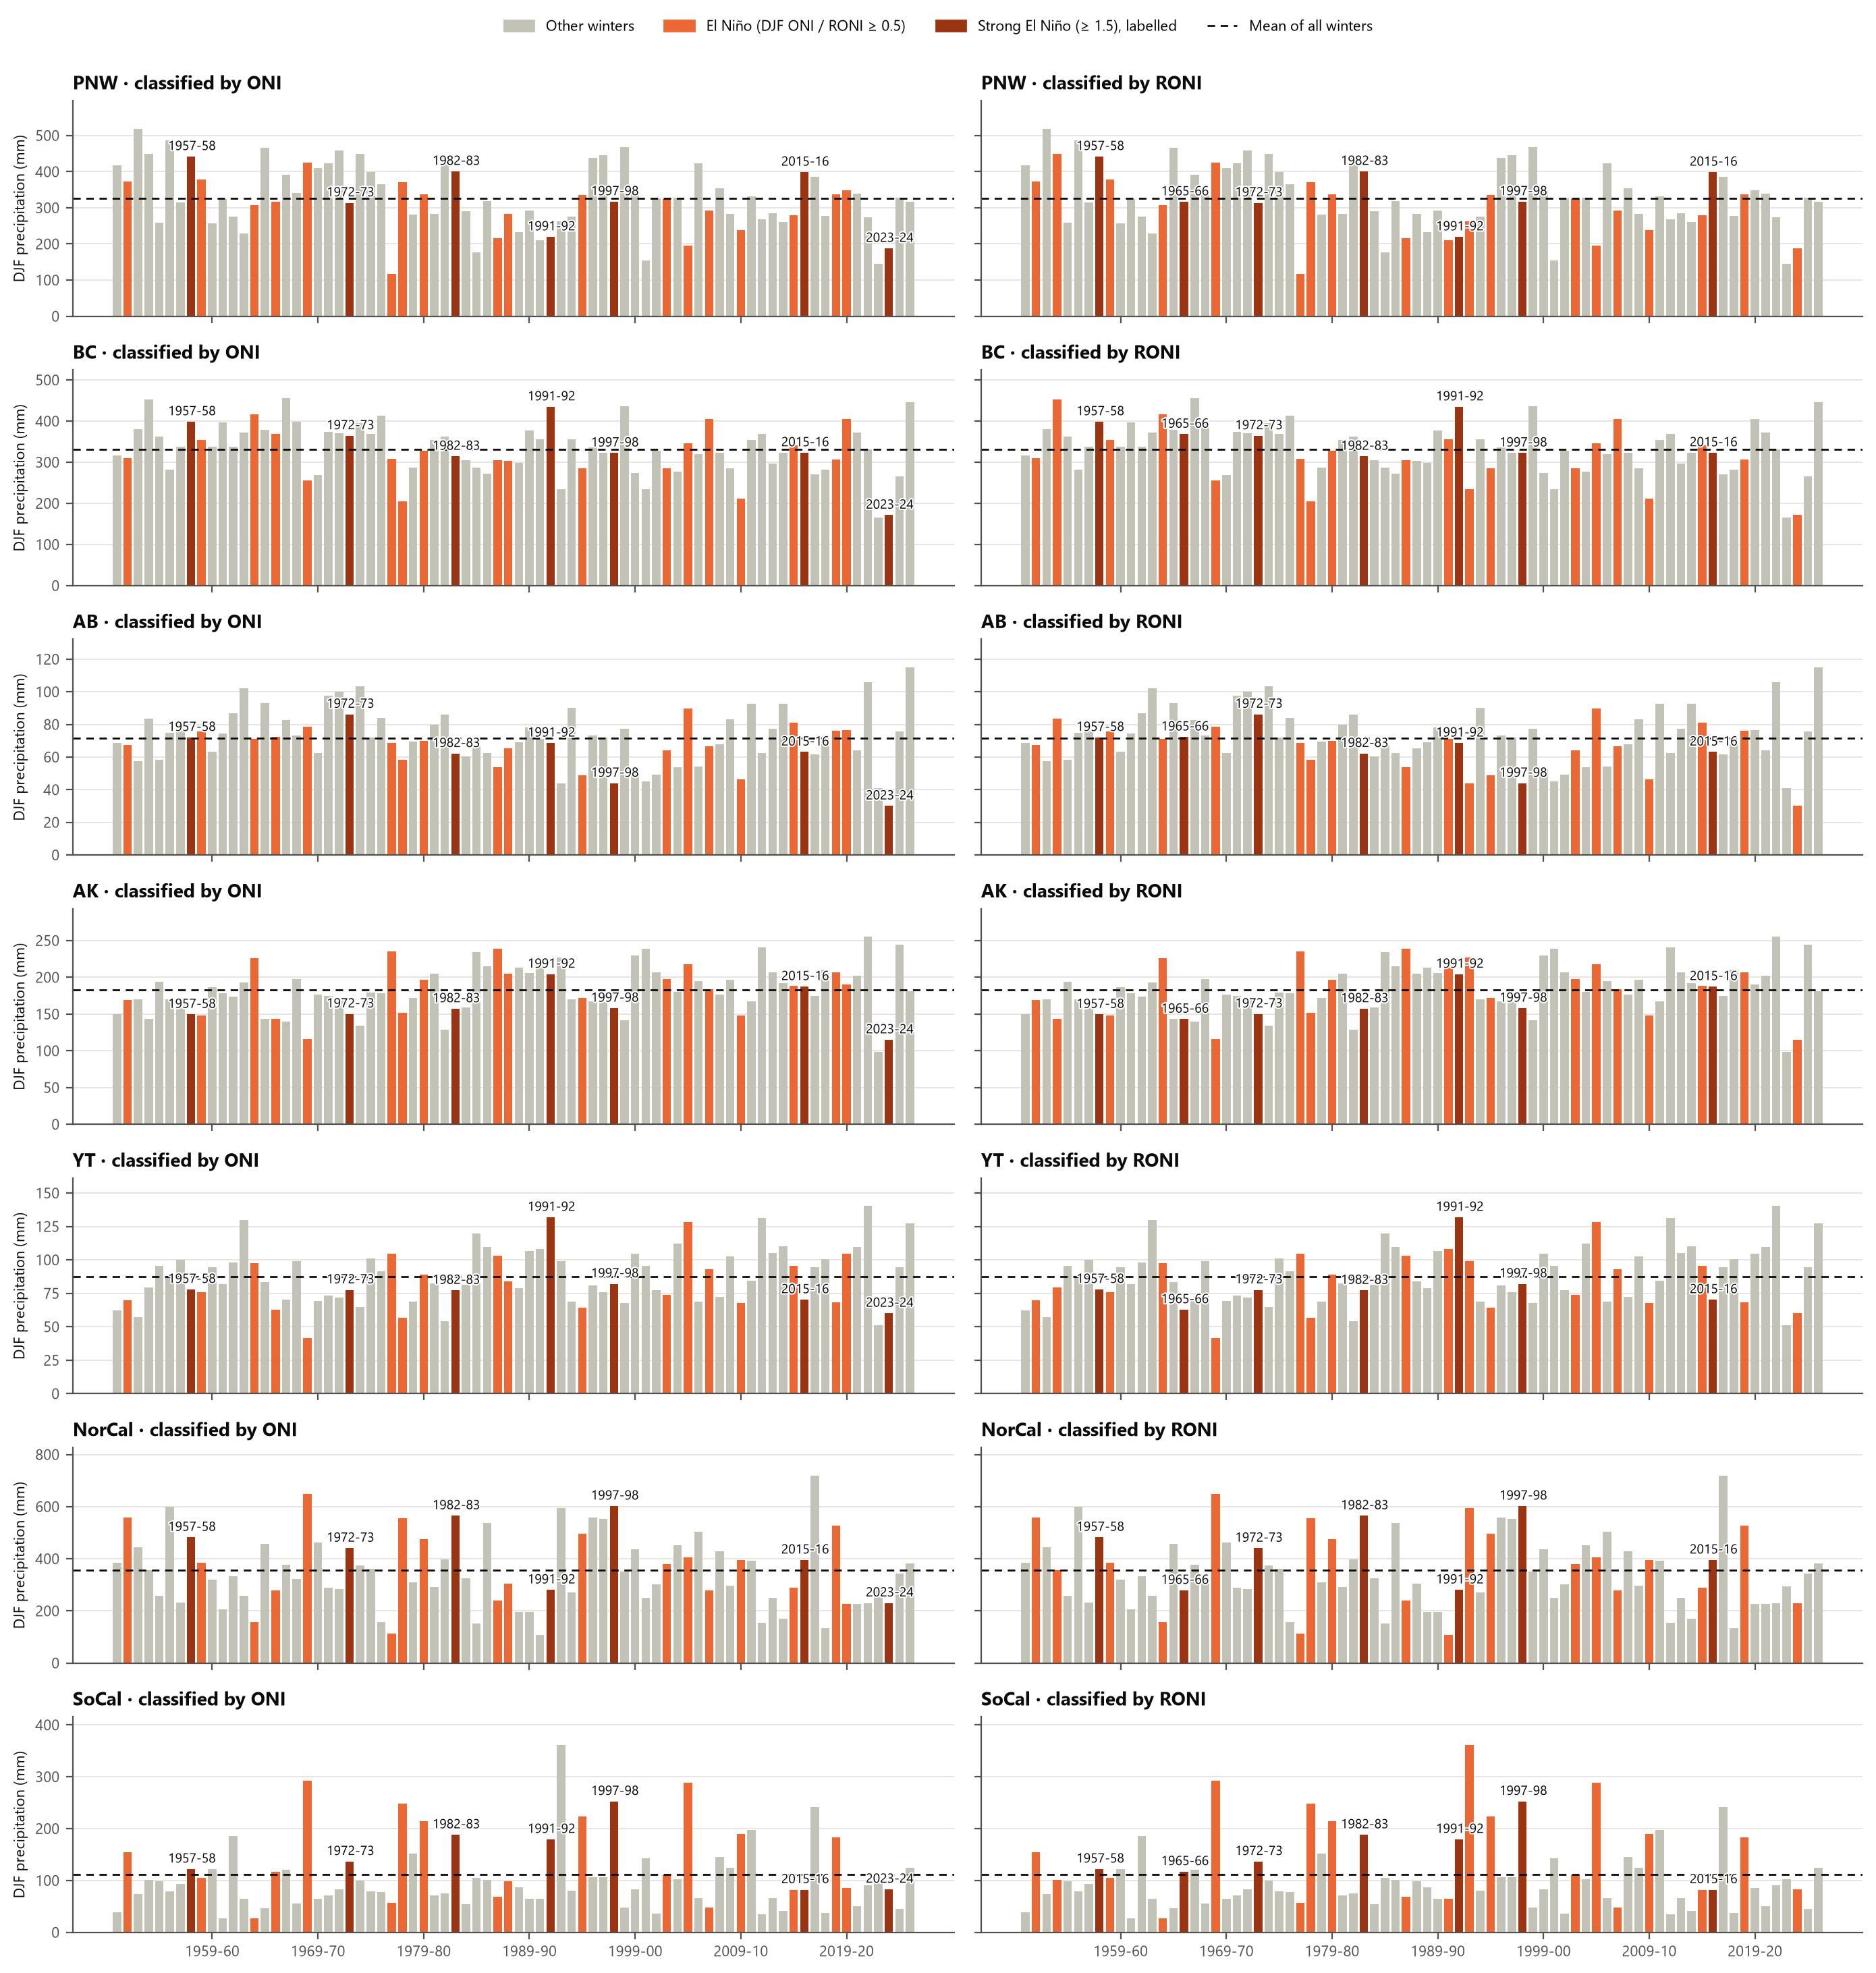

In [8]:
out = winter_figures.comparison_figure(tables)
display(Image(out))

## Sanity check: the El Niño dipole, described (no tests)

Expected: El Niño winters drier than usual in PNW, BC and AB, wetter in SoCal;
NorCal in between. Differences are shown in mm, as % of the all-winter mean,
and in standard deviations of all winters. These are descriptive numbers only;
the tests come after the freeze.

In [9]:
cols = ["region", "n_el_nino", "n_strong", "n_neutral", "mean_all", "mean_el_nino",
        "mean_neutral", "mean_strong", "mean_la_nina", "nino_minus_neutral",
        "nino_minus_neutral_pct", "nino_minus_neutral_sd", "nino_minus_all_pct",
        "strong_minus_all_pct", "strong_minus_all_sd", "nino_share_below_median"]
summaries = {name: phase_summary(t, "precip_djf_mm")[cols] for name, t in tables.items()}
for name, s in summaries.items():
    print(name)
    display(s.set_index("region").round(2))

ONI


,n_el_nino,n_strong,n_neutral,mean_all,mean_el_nino,mean_neutral,mean_strong,mean_la_nina,nino_minus_neutral,nino_minus_neutral_pct,nino_minus_neutral_sd,nino_minus_all_pct,strong_minus_all_pct,strong_minus_all_sd,nino_share_below_median
region,,,,,,,,,,,,,,,
PNW,25,7,25,326.67,310.08,328.39,325.56,340.98,-18.31,-5.61,-0.21,-5.08,-0.34,-0.01,0.56
BC,25,7,25,331.08,322.75,338.62,332.62,331.83,-15.88,-4.80,-0.26,-2.52,0.47,0.03,0.60
AB,25,7,25,71.48,66.24,74.69,60.86,73.43,-8.45,-11.82,-0.52,-7.33,-14.86,-0.66,0.64
AK,25,7,25,182.74,178.13,184.73,160.14,185.26,-6.60,-3.61,-0.20,-2.52,-12.37,-0.69,0.48
YT,25,7,25,87.53,82.29,91.01,82.43,89.23,-8.72,-9.96,-0.41,-5.99,-5.83,-0.24,0.60
NorCal,25,7,25,354.99,388.21,354.39,427.89,323.63,33.82,9.53,0.24,9.36,20.53,0.53,0.40
SoCal,25,7,25,110.88,145.51,103.50,149.09,84.68,42.02,37.89,0.62,31.24,34.46,0.56,0.32


RONI


,n_el_nino,n_strong,n_neutral,mean_all,mean_el_nino,mean_neutral,mean_strong,mean_la_nina,nino_minus_neutral,nino_minus_neutral_pct,nino_minus_neutral_sd,nino_minus_all_pct,strong_minus_all_pct,strong_minus_all_sd,nino_share_below_median
region,,,,,,,,,,,,,,,
PNW,26,7,26,326.67,309.30,344.09,343.92,326.63,-34.79,-10.65,-0.40,-5.32,5.28,0.20,0.58
BC,26,7,26,331.08,323.14,347.96,360.76,321.38,-24.82,-7.50,-0.40,-2.40,8.97,0.48,0.58
AB,26,7,26,71.48,65.88,74.84,66.90,73.91,-8.96,-12.54,-0.55,-7.84,-6.41,-0.28,0.62
AK,26,7,26,182.74,178.77,178.96,164.16,191.15,-0.19,-0.10,-0.01,-2.18,-10.17,-0.56,0.50
YT,26,7,26,87.53,82.91,87.26,82.82,92.83,-4.35,-4.98,-0.21,-5.28,-5.38,-0.22,0.62
NorCal,26,7,26,354.99,393.57,334.67,434.81,335.21,58.90,16.59,0.42,10.87,22.49,0.58,0.35
SoCal,26,7,26,110.88,153.08,83.39,153.94,94.94,69.70,62.86,1.02,38.06,38.83,0.63,0.31
